# Additional trial-1 trajectory review

Browse up to 30 additional complete five-setting questions per benchmark, excluding the two current manuscript cases. Every question displays off/155/001/004/046, with simulator and actor embedded separately. These are existing saved traces, not new rollouts.

Selection prioritizes cases with four or more paired simulator–actor exchanges: first the number of settings reaching four, then minimum and total exchange counts, with a fixed hash tie-break. Cases where no setting reaches four are excluded. This length-enriched subset is exploratory, not representative. Manual selections are exploratory illustrations; aggregate estimates remain unchanged. Embedding: frozen Qwen3-Embedding-0.6B, normalized 1024-dimensional vectors. Each question–role UMAP uses all observed trial-1 messages from all five settings; local axes are not comparable across plots. Use cosine metric, n_neighbors=min(15, n_messages−1), min_dist=0.1, 500 epochs, spectral initialization, random_state=42 and one computation thread. UMAP does not provide explained-variance percentages. Cluster gaps and path lengths are not quantitative effect sizes.

In [1]:
from pathlib import Path
import sys, json, csv, hashlib, re, subprocess
import numpy as np
import fitz
from IPython.display import display, Markdown, SVG
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0,str(ROOT/'Experiment/01_behavioral_diversity/code/semantic'))
import gallery
# Set True to reproduce all SVGs, PDFs and the private HTML from cached embeddings.
REBUILD=False
if REBUILD or not (gallery.DEST/'index.html').exists():
    gallery.build()
manifest=json.loads((gallery.PUBLIC/'manifest.json').read_text())
assert manifest['projection_method']=='UMAP'
print(manifest['selection_rule'])
print('UMAP parameters:',manifest['projection_settings'])
print('UMAP version:',manifest['umap_learn_version'])
print('Embedding:',manifest['embedding_model'],manifest['embedding_revision'])


Require complete trial-1 data for five settings; exclude the two main-figure cases. Retain questions with at least four paired simulator–actor exchanges in at least one setting. Rank by number of settings reaching four exchanges, then minimum and total paired exchanges across settings, all descending; hash breaks ties. Take up to 30 per benchmark. Selection is length-enriched and exploratory.
UMAP parameters: {'n_components': 2, 'n_neighbors': 15, 'min_dist': 0.1, 'metric': 'cosine', 'random_state': 42, 'transform_seed': 42, 'n_epochs': 500, 'init': 'spectral', 'n_jobs': 1}
UMAP version: 0.5.12
Embedding: Qwen/Qwen3-Embedding-0.6B 97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3


In [2]:
table=['| Benchmark | Requested | Eligible long cases | Displayed |','|---|---:|---:|---:|']
for r in manifest['coverage']:
    table.append(f"| {gallery.NAMES[r['source']]} | 30 | {r['long_eligible']} | {r['selected']} |")
display(Markdown('\n'.join(table)))
display(Markdown('[Open interactive review gallery](../../runs/semantic-review/index.html) — select favorites, add notes, then export JSON.'))
print('Complete cases:',len(manifest['cases']))
print('Persona interaction traces:',len(manifest['cases'])*5)


| Benchmark | Requested | Eligible long cases | Displayed |
|---|---:|---:|---:|
| ASI-Bench | 30 | 0 | 0 |
| BixBench | 30 | 1 | 1 |
| DiscoveryBench | 30 | 0 | 0 |
| EXP-Bench | 30 | 0 | 0 |
| SciConvBench | 30 | 21 | 21 |

[Open interactive review gallery](../../runs/semantic-review/index.html) — select favorites, add notes, then export JSON.

Complete cases: 22
Persona interaction traces: 110


## One preview per benchmark
The HTML contains every case and the saved messages; these previews show the first selected question per source. PDF books contain one page per question.

### BixBench
[All pages (PDF)](../../runs/semantic-review/pdf/bixbench.pdf)

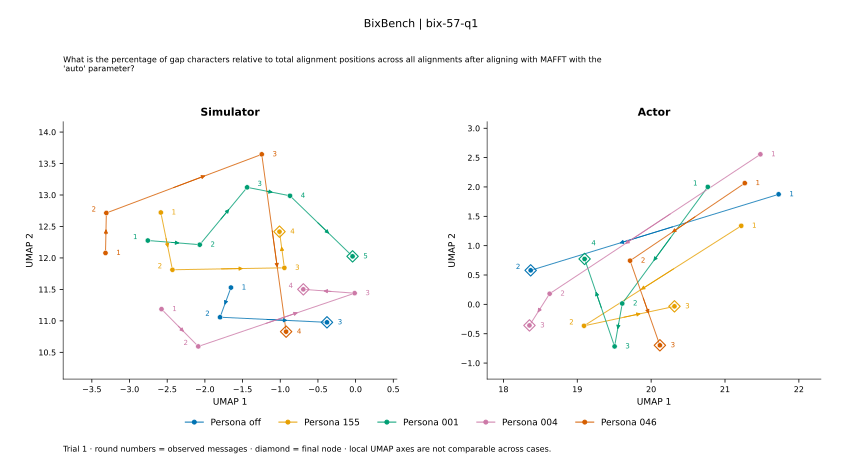

### SciConvBench
[All pages (PDF)](../../runs/semantic-review/pdf/sciconvbench.pdf)

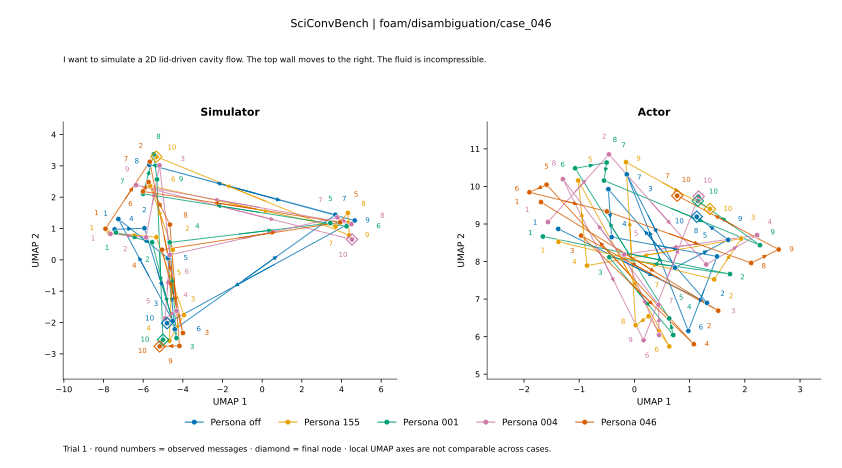

In [3]:
for source in gallery.SOURCES:
    case=next((c for c in manifest['cases'] if c['source']==source),None)
    if case is None: continue
    display(Markdown(f"### {gallery.NAMES[source]}\n[All pages (PDF)](../../runs/semantic-review/pdf/{source}.pdf)"))
    display(SVG(filename=str(gallery.DEST/'plots'/f"{case['id']}.svg")))


## Validate coverage and provenance
Check complete role/persona coverage, trial index, source counts, clickable nodes, PDF page counts, finite coordinates, exclusion of previous cases, and unchanged aggregate manuscript artifacts.

In [4]:
html=(gallery.DEST/'index.html').read_text()
payload=json.loads(re.search(r'<script id="data" type="application/json">(.*?)</script>',html,re.S).group(1))
assert len(payload['cases'])==sum(r['selected'] for r in manifest['coverage'])
assert len(payload['cases'])>0
previous={(c['source'],c['task_id']) for c in json.loads((gallery.OUT/'cases.json').read_text())}
assert not previous & {(c['source'],c['task_id']) for c in payload['cases']}
for case in payload['cases']:
    assert '>UMAP 1</text>' in case['svg'] and '>UMAP 2</text>' in case['svg']
    assert all(p['method']=='UMAP' and p['settings']['random_state']==42 for p in case['projection'])
    assert {m['trial'] for m in case['messages']}=={1}
    actual={a:len({m['round'] for m in case['messages'] if m['arm']==a and m['role']=='simulator'} & {m['round'] for m in case['messages'] if m['arm']==a and m['role']=='actor'}) for a in payload['config']['arms']}
    assert actual==case['paired_exchanges']
    assert sum(v>=4 for v in actual.values())==case['long_persona_count']>=1
    for role in ['simulator','actor']:
        assert {m['arm'] for m in case['messages'] if m['role']==role}==set(payload['config']['arms'])
    assert case['svg'].count('class="message-node"')==len(case['messages'])
for r in manifest['coverage']:
    if not r['selected']:
        assert not (gallery.DEST/'pdf'/f"{r['source']}.pdf").exists()
        continue
    with fitz.open(gallery.DEST/'pdf'/f"{r['source']}.pdf") as doc:
        assert len(doc)==r['selected']
coords=list(csv.DictReader((gallery.PUBLIC/'coordinates.csv').open()))
assert np.isfinite([[float(r['umap1']),float(r['umap2'])] for r in coords]).all()
assert len(coords)==sum(len(c['messages']) for c in payload['cases'])
qa=json.loads((gallery.BASE/'figures/semantic/qa/validation.json').read_text())
for path,digest in qa['sha256'].items():
    if path.endswith('.ipynb'): continue  # QA predates the final notebook save.
    assert hashlib.sha256((gallery.BASE/path).read_bytes()).hexdigest()==digest,path
script=html.split('</script><script>')[1].split('</script>')[0]
script_path=Path('/tmp/psb-gallery-check.js');script_path.write_text(script)
subprocess.run(['node','--check',str(script_path)],check=True,capture_output=True)
result=json.loads((gallery.PUBLIC/'validation.json').read_text())
result.update(projection_method='UMAP',fixed_seed_verified=True,pdf_page_counts_verified=True,clickable_node_counts_verified=True,finite_coordinates=True,main_artifact_hashes_unchanged=True,javascript_syntax='passed',browser_interaction_test='not performed',notebook_executed=True)
gallery.write_json(gallery.PUBLIC/'validation.json',result)
print(json.dumps(result,indent=2))


{
  "cases": 22,
  "question_pair_duplicates": 0,
  "existing_main_cases_excluded": true,
  "all_five_personas_per_role": true,
  "trial": 1,
  "private_message_text_location": "ignored runs/semantic-review/index.html",
  "new_model_calls": 0,
  "umap_fit": "Each question and role independently, all observed trial-1 rounds and five settings",
  "source_counts": {
    "bixbench": 1,
    "sciconvbench": 21
  },
  "coordinate_rows": 1173,
  "projection_method": "UMAP",
  "fixed_seed_verified": true,
  "pdf_page_counts_verified": true,
  "clickable_node_counts_verified": true,
  "finite_coordinates": true,
  "main_artifact_hashes_unchanged": true,
  "javascript_syntax": "passed",
  "browser_interaction_test": "not performed",
  "notebook_executed": true
}


## Selecting illustrations
Use the gallery to inspect messages, star cases and add reasons for selection. Export the JSON to preserve choices beyond browser storage. Report eventual paper examples as manually selected illustrations. The full heatmaps and confidence intervals are unaffected. Full transcripts remain in ignored `runs/semantic-review/`; tracked numeric manifests contain no message text.